<a href="https://colab.research.google.com/github/DinaKSari/244107020072_PEMBELAJARAN_MESIN/blob/main/PBL_TG6_244107020072_DINA_KUMALA_SARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# praktikum 1

In [27]:
# import package
import numpy as np
import pandas as pd

In [28]:
# baca data dari file CSV
data = pd.read_csv('lettuce.csv', encoding='latin1')
data.head()

,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
0,1,8/3/2023,33.4,53,582,6.4,1,92.12,0.53
1,1,8/4/2023,33.5,53,451,6.1,2,92.30,0.53
2,1,8/5/2023,33.4,59,678,6.4,3,92.12,0.59
3,1,8/6/2023,33.4,68,420,6.4,4,92.12,0.68
4,1,8/7/2023,33.4,74,637,6.5,5,92.12,0.74


In [29]:
# melihat beberapa data awal
data.head()

# mengecek ukuran data
data.shape

# informasi tentang data
data.info()

# deskripsi data
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3169 entries, 0 to 3168
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Plant_ID          3169 non-null   int64  
 1   Date              3169 non-null   object 
 2   Temperature (°C)  3169 non-null   float64
 3   Humidity (%)      3169 non-null   int64  
 4   TDS Value (ppm)   3169 non-null   int64  
 5   pH Level          3169 non-null   float64
 6   Growth Days       3169 non-null   int64  
 7   Temperature (F)   3169 non-null   float64
 8   Humidity          3169 non-null   float64
dtypes: float64(4), int64(4), object(1)
memory usage: 222.9+ KB


,Plant_ID,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
count,3169.000000,3169.000000,3169.000000,3169.000000,3169.000000,3169.000000,3169.000000,3169.000000
mean,35.441780,28.142222,64.873462,598.045440,6.399211,23.141054,82.655999,0.648735
std,20.243433,4.670521,8.988985,115.713047,0.234418,13.077107,8.406938,0.089890
min,1.000000,18.000000,50.000000,400.000000,6.000000,1.000000,64.400000,0.500000
25%,18.000000,23.600000,57.000000,498.000000,6.200000,12.000000,74.480000,0.570000
50%,35.000000,30.200000,65.000000,593.000000,6.400000,23.000000,86.360000,0.650000
75%,53.000000,31.500000,73.000000,699.000000,6.600000,34.000000,88.700000,0.730000
max,70.000000,33.500000,80.000000,800.000000,6.800000,48.000000,92.300000,0.800000


In [30]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

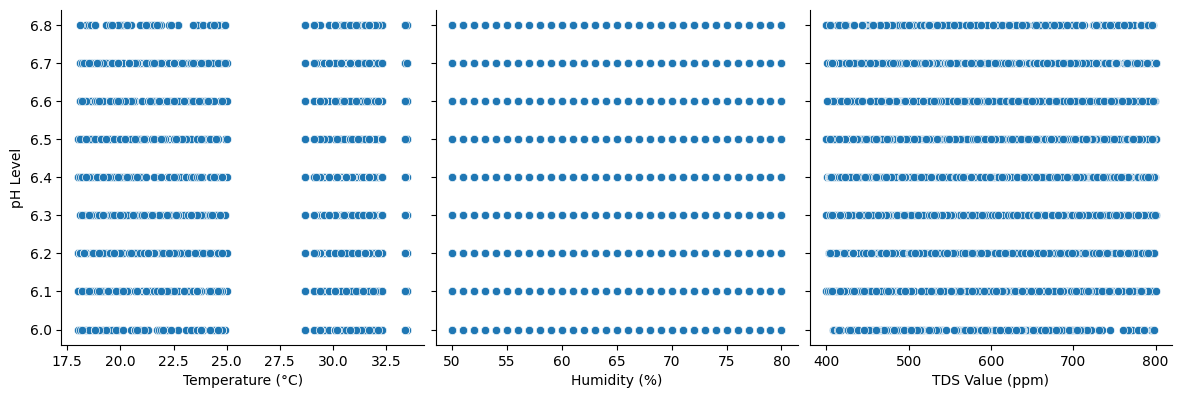

In [31]:
# visualisasi data dengan pairplot (menggunakan dataset lettuce)
sns.pairplot(data, x_vars=['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)'],
             y_vars='pH Level', height=4, aspect=1, kind='scatter')
plt.show()

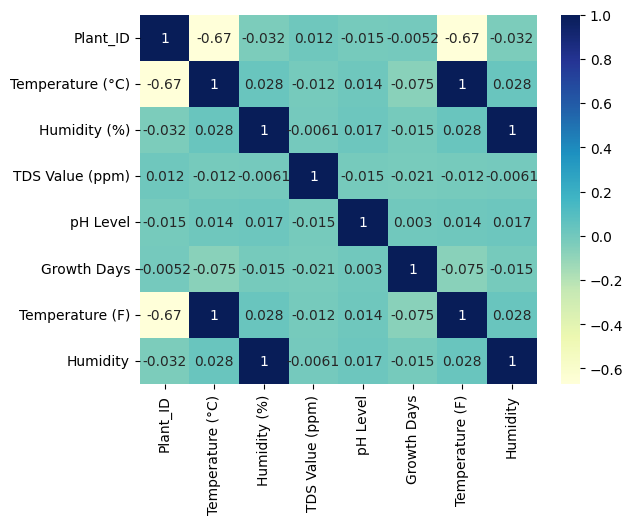

In [32]:
# visualisasi korelasi dengan heatmap
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

In [33]:
# Membuat variabel bebas X dan y menggunakan dataset lettuce
X = data['Temperature (°C)']
y = data['pH Level']

In [34]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

In [35]:
# Training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

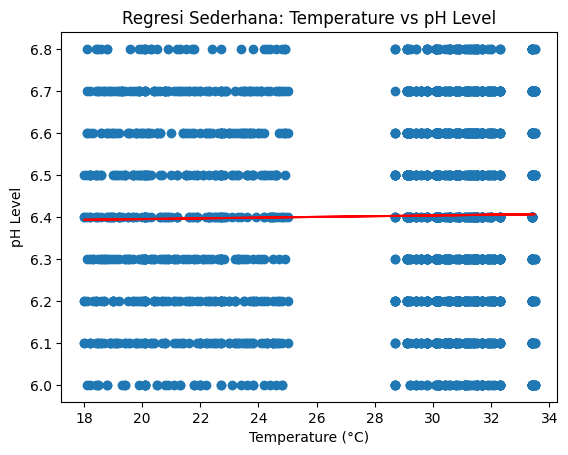

In [36]:
# Visualisasi garis regresi untuk dataset lettuce
plt.scatter(X_train, y_train)
# Menghitung koefisien regresi sederhana secara dinamis agar garis yang digambar akurat
coef = np.polyfit(X_train, y_train, 1)
plt.plot(X_train, coef[1] + coef[0]*X_train, 'r')
plt.title('Regresi Sederhana: Temperature vs pH Level')
plt.xlabel('Temperature (°C)')
plt.ylabel('pH Level')
plt.show()

In [37]:
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

/tmp/ipykernel_695/594495671.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(res, bins=15)


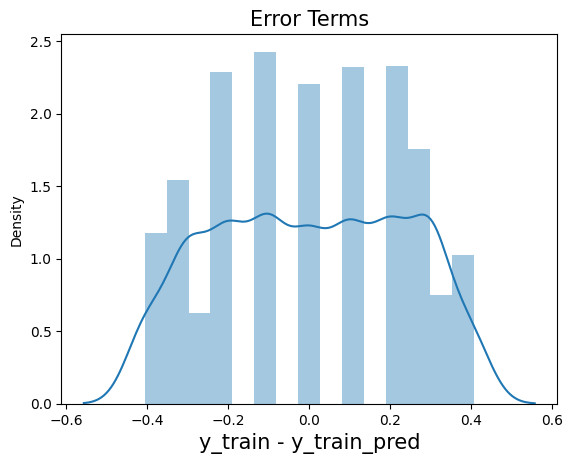

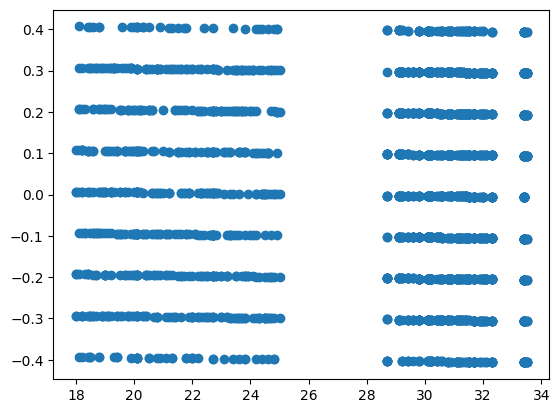

In [38]:
# Histogram residual
fig = plt.figure()
sns.distplot(res, bins=15)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual
plt.scatter(X_train, res)
plt.show()

In [39]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

In [40]:
# Hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)

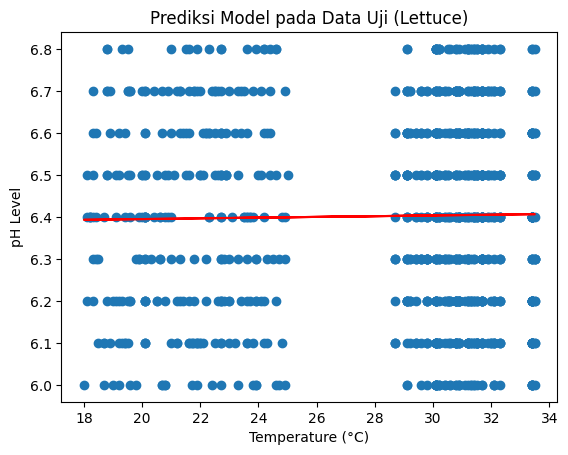

In [41]:
# Visualisasi data uji dan hasil prediksi untuk dataset lettuce
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.title('Prediksi Model pada Data Uji (Lettuce)')
plt.xlabel('Temperature (°C)')
plt.ylabel('pH Level')
plt.show()

# praktikum 2

In [42]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [43]:
# Menggunakan subset data lettuce untuk contoh Support Vector Regression (SVR)
X = data['Temperature (°C)'].values.reshape(-1, 1)
y = data['pH Level'].values.reshape(-1, 1)

In [44]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

In [45]:
# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

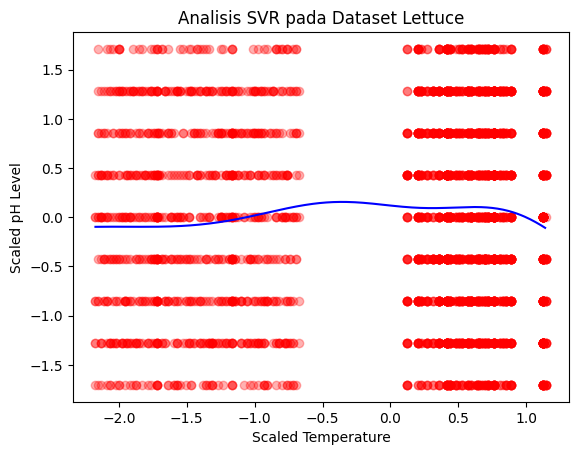

In [46]:
# Visualisasi hasil SVR menggunakan dataset lettuce dengan memperbaiki min/max scalar
X_grid = np.arange(X.min(), X.max(), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red', alpha=0.3)
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Analisis SVR pada Dataset Lettuce')
plt.xlabel('Scaled Temperature')
plt.ylabel('Scaled pH Level')
plt.show()

In [47]:
# Prediksi hasil SVR dengan nilai suhu (misalnya 28 °C)
suhu_prediksi = np.array([[28.0]])
suhu_prediksi_scaled = sc_X.transform(suhu_prediksi)
gaji_prediksi = regressor.predict(suhu_prediksi_scaled)
# Kembalikan hasil prediksi ke skala aslinya
pH_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

In [48]:
# Menampilkan hasil prediksi SVR
print("Prediksi pH Level untuk Temperature 28°C:", pH_prediksi[0][0])

Prediksi pH Level untuk Temperature 28°C: 6.428128479368074


In [49]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.8626875350412485
MSE: 1.0025525662067616
RMSE: 1.0012754696919133
R-squared: -0.002552566206761586


# tugas praktikum
Tugas Praktikum: Multiple Linear Regression dengan Dataset Medical Cost Personal Datasets

Instruksi Umum:

Anda akan menggunakan dataset "Medical Cost Personal Datasets". Pastikan Anda telah mengunduh dataset ini.

Gunakan bahasa pemrograman Python dan library yang sesuai seperti NumPy, Pandas, Matplotlib dan Scikit-Learn untuk melakukan analisis regresi dan SVR.

Tugas 1: Multiple Linear Regression

Bagi dataset menjadi data latih (train) dan data uji (test) dengan proporsi yang sesuai.

Lakukan feature scaling jika diperlukan.

Buat model multiple linear regression menggunakan Scikit-Learn.

Latih model pada data latih dan lakukan prediksi pada data uji.

Evaluasi model dengan menghitung metrik seperti R-squared, MSE, dan MAE. Tampilkan hasil evaluasi.

Catatan Tambahan:

Pastikan untuk memberikan penjelasan singkat tentang dataset yang digunakan, termasuk deskripsi variabel-variabel yang relevan.

Tampilkan visualisasi data yang relevan seperti scatter plot atau grafik lainnya jika diperlukan untuk pemahaman yang lebih baik.

Analisis hasil yang Anda dapatkan dalam tugas praktikum Anda.

Deskripsi & Informasi Awal Dataset Lettuce
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3169 entries, 0 to 3168
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Plant_ID          3169 non-null   int64  
 1   Date              3169 non-null   object 
 2   Temperature (°C)  3169 non-null   float64
 3   Humidity (%)      3169 non-null   int64  
 4   TDS Value (ppm)   3169 non-null   int64  
 5   pH Level          3169 non-null   float64
 6   Growth Days       3169 non-null   int64  
 7   Temperature (F)   3169 non-null   float64
 8   Humidity          3169 non-null   float64
dtypes: float64(4), int64(4), object(1)
memory usage: 222.9+ KB
None

Statistik Deskriptif
          Plant_ID  Temperature (°C)  Humidity (%)  TDS Value (ppm)  \
count  3169.000000       3169.000000   3169.000000      3169.000000   
mean     35.441780         28.142222     64.873462       598.045440   
std      20.243433          4.

<Figure size 1000x800 with 0 Axes>

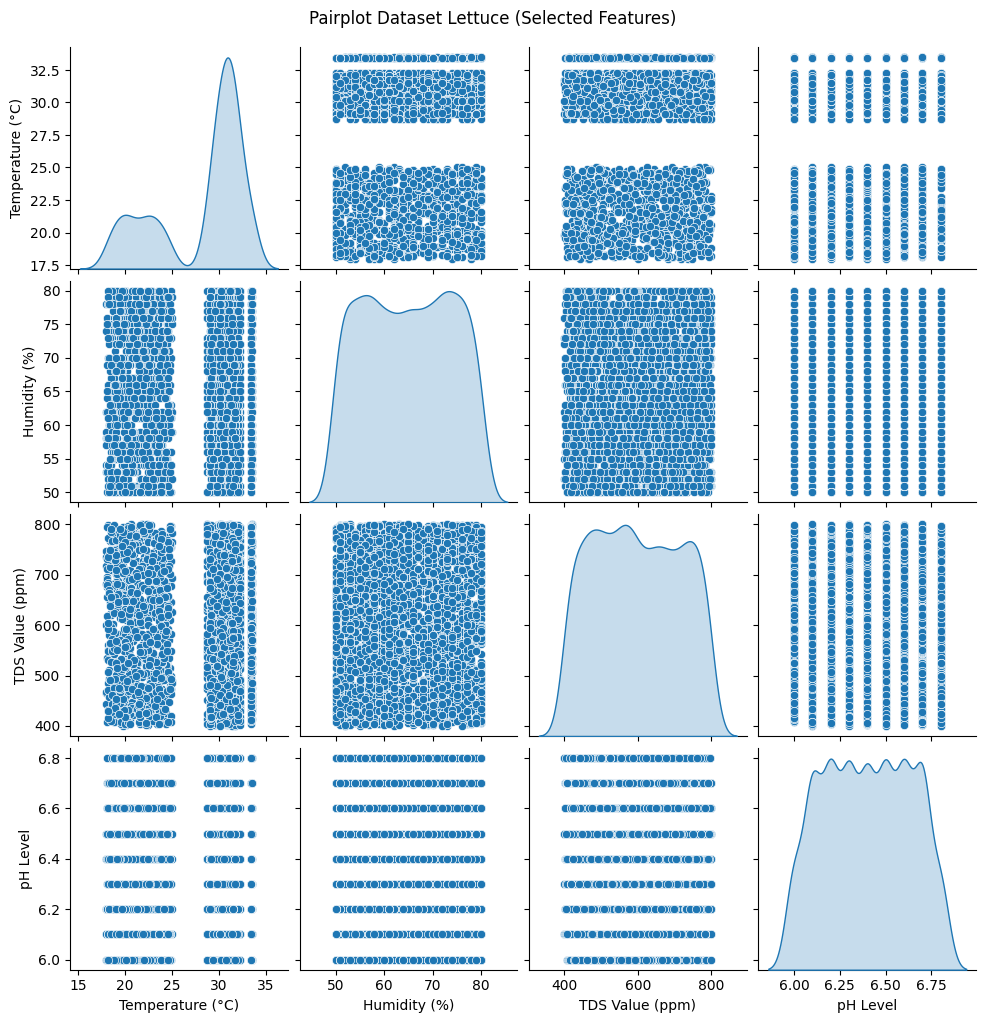

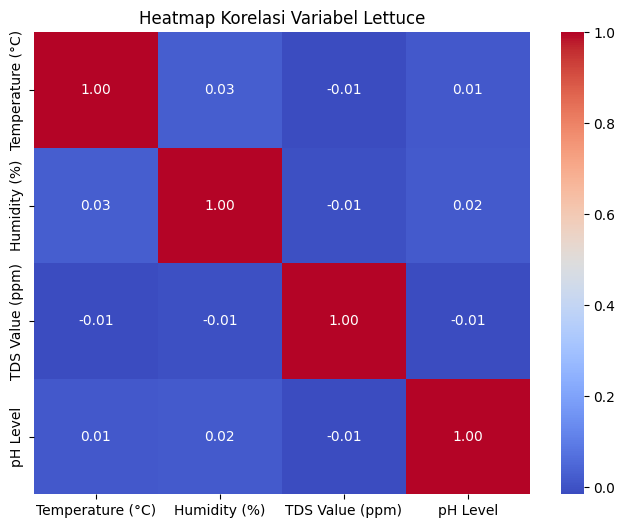

Hasil Evaluasi Model (Lettuce Dataset)
R-squared (R2) : -0.0045
Mean Squared Error (MSE) : 0.0543
Mean Absolute Error (MAE) : 0.1988
Root Mean Squared Error (RMSE) : 0.2330


In [50]:
# 1. Import library yang diperlukan
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 2. Menggunakan dataset lettuce yang sudah dimuat sebelumnya
df = data.copy()

print("Deskripsi & Informasi Awal Dataset Lettuce")
print(df.info())
print("\nStatistik Deskriptif")
print(df.describe())

# 3. Visualisasi Data Relevan
plt.figure(figsize=(10, 8))
sns.pairplot(df[['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level']], diag_kind='kde')
plt.suptitle("Pairplot Dataset Lettuce (Selected Features)", y=1.02)
plt.show()

# Visualisasi Korelasi
plt.figure(figsize=(8, 6))
sns.heatmap(df[['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Heatmap Korelasi Variabel Lettuce")
plt.show()

# 4. Identifikasi Variabel Bebas (Fitur) dan Variabel Target
X = df[['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)']]
y = df['pH Level']

# 5. Membagi Dataset menjadi Data Latih dan Data Uji (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. Preprocessing & Feature Scaling
numeric_features = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)']
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features)
    ]
)

# Fit dan transform pada data latih, transform pada data uji
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

# 7. Membuat dan Melatih Model Multiple Linear Regression
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# 8. Melakukan Prediksi
y_pred = model.predict(X_test_scaled)

# 9. Evaluasi Model
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Hasil Evaluasi Model (Lettuce Dataset)")
print(f"R-squared (R2) : {r2:.4f}")
print(f"Mean Squared Error (MSE) : {mse:.4f}")
print(f"Mean Absolute Error (MAE) : {mae:.4f}")
print(f"Root Mean Squared Error (RMSE) : {rmse:.4f}")

```markdown
# Penjelasan Singkat Dataset Lettuce:
Dataset ini berisi data kondisi lingkungan pertumbuhan tanaman selada dengan variabel:
- Temperature (°C): Suhu lingkungan dalam derajat Celsius
- Humidity (%): Kelembapan udara dalam persen
- TDS Value (ppm): Total Dissolved Solids dalam air nutrisi
- pH Level: Tingkat keasaman larutan nutrisi (Target Variable)
```

```markdown
# Hasil Analisis (Lettuce Dataset)
1. Berdasarkan korelasi, kita menganalisis pengaruh dari kombinasi fitur suhu, kelembapan, dan nilai TDS terhadap tingkat pH.
2. Model Multiple Linear Regression memprediksi nilai pH berdasarkan kondisi lingkungan pertumbuhan selada.
```